# Practical 3: Multiple Linear Regression (MSE, RMSE, R²)

**Subject:** Machine Learning  |  **Type:** Supervised learning, regression

## Aim
Develop a **multiple linear regression** model using a suitable real-world open-access dataset and assess its predictive capability using regression evaluation metrics such as **MSE, RMSE and R²**.

## Dataset
**Diabetes dataset** (scikit-learn, real clinical data): 442 patients, **10 features** (age, sex, bmi, bp, s1 to s6 blood serum measurements). The target is a numeric measure of **disease progression one year after baseline**. It is built in, so no download is needed.

> The 10 features in this dataset are already mean-centred and scaled by scikit-learn, so no extra scaling is needed for plain linear regression.
> To use California Housing instead, replace the loading cell with `fetch_california_housing(as_frame=True)` (needs internet) and use `MedHouseVal` as the target. Everything else stays the same.

## Steps
1. Load data and explore (summary, correlation heatmap)
2. Split into train/test
3. Fit `LinearRegression`, inspect coefficients
4. Predict and compute MSE, RMSE, MAE, R², adjusted R²
5. Graphs: actual vs predicted, residual plot, residual histogram
6. Check multicollinearity (VIF), cross-validation
7. Verify the result with the normal equation by hand

## Step 0: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")

## Step 1: Load data and explore

In [2]:
data = load_diabetes(as_frame=True)
df = data.frame.rename(columns={"target": "progression"})
print("Shape:", df.shape)
df.head()

Shape: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [3]:
print("Missing values:", df.isnull().sum().sum())
df.describe().round(3)

Missing values: 0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,progression
count,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000,442.000
mean,-0.000,0.000,-0.000,-0.000,-0.000,0.000,-0.000,-0.000,0.000,0.000,152.133
std,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,0.048,77.093
min,-0.107,-0.045,-0.090,-0.112,-0.127,-0.116,-0.102,-0.076,-0.126,-0.138,25.000
25%,-0.037,-0.045,-0.034,-0.037,-0.034,-0.030,-0.035,-0.039,-0.033,-0.033,87.000
50%,0.005,-0.045,-0.007,-0.006,-0.004,-0.004,-0.007,-0.003,-0.002,-0.001,140.500
75%,0.038,0.051,0.031,0.036,0.028,0.030,0.029,0.034,0.032,0.028,211.500
max,0.111,0.051,0.171,0.132,0.154,0.199,0.181,0.185,0.134,0.136,346.000


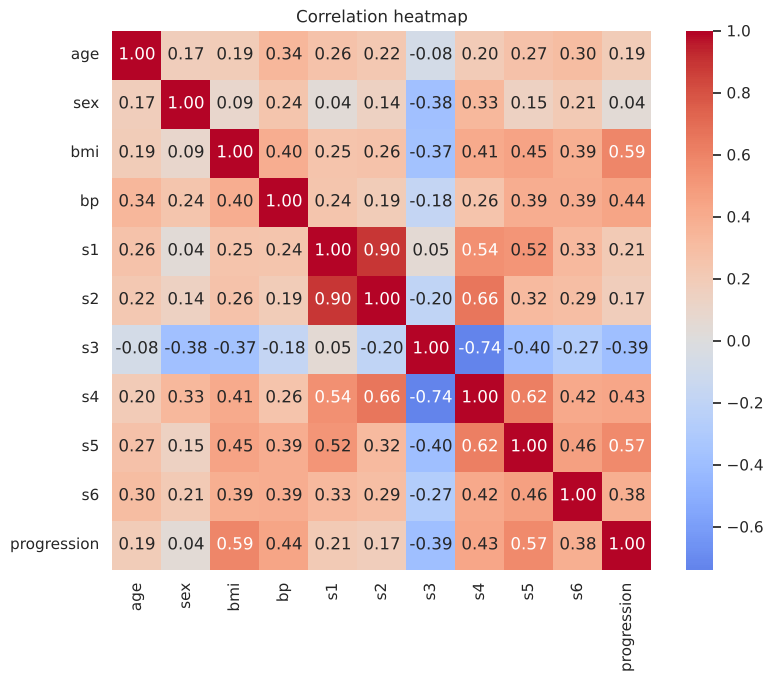

In [4]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation heatmap")
plt.show()

**How to read the heatmap:** each cell is the correlation (-1 to +1) between two variables. Red is positive, blue is negative.
- Correlation of each feature with `progression` (last row): `bmi` and `s5` are the strongest positive predictors, `bp` is also positive.
- Correlation between features: `s1` and `s2` are strongly correlated (about 0.9), and `s3` is negatively related to `s4`. This signals **multicollinearity**, which we check later with VIF.

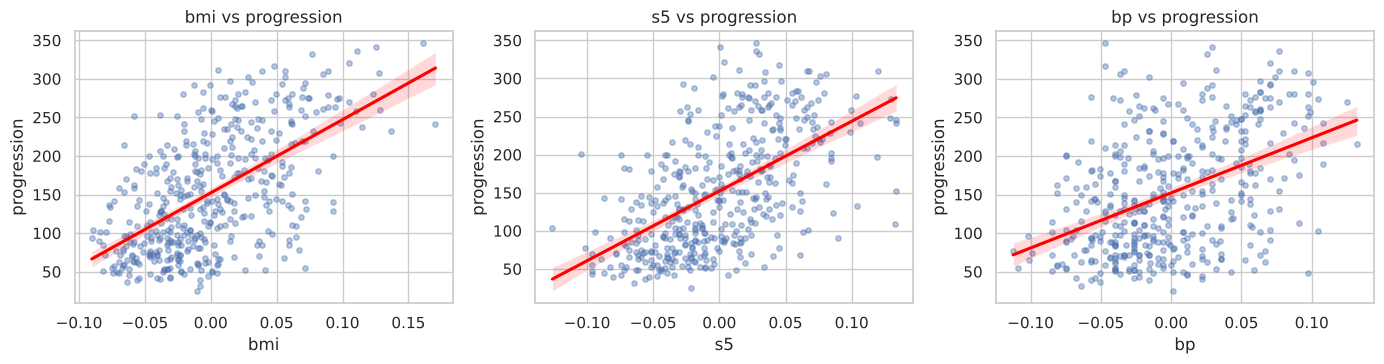

In [5]:
X = df.drop(columns="progression")
y = df["progression"]

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, col in zip(ax, ["bmi", "s5", "bp"]):
    sns.regplot(x=df[col], y=y, ax=a, scatter_kws={"alpha": 0.4, "s": 15}, line_kws={"color": "red"})
    a.set_title(f"{col} vs progression")
plt.tight_layout(); plt.show()

**How to read these:** each dot is a patient and the red line is the best-fit line for that single feature. An upward slope means higher values of that feature go with higher disease progression. Scatter around the line means a single feature explains only part of the variation, which is why we use several features together.

## Step 2: Train/test split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (353, 10) | Test: (89, 10)


## Step 3: Fit the model

$$\hat{y} = b_0 + b_1 x_1 + b_2 x_2 + \dots + b_{10} x_{10}$$

The coefficients are found by **Ordinary Least Squares (OLS)**, which minimises the sum of squared residuals.

Intercept (b0): 151.346
s1    -931.489
sex   -241.964
age     37.904
s6      48.671
s3     163.420
s4     275.318
bp     347.704
s2     518.062
bmi    542.429
s5     736.199
dtype: float64


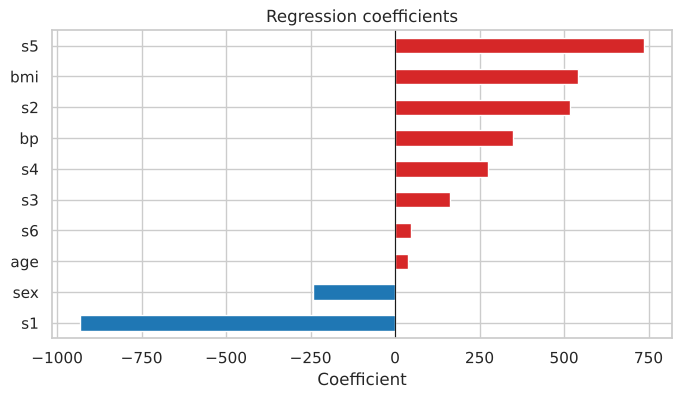

In [7]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept (b0): %.3f" % model.intercept_)
coef = pd.Series(model.coef_, index=X.columns).sort_values()
print(coef.round(3))

plt.figure(figsize=(8, 4))
coef.plot(kind="barh", color=np.where(coef > 0, "tab:red", "tab:blue"))
plt.axvline(0, color="k", lw=0.8); plt.title("Regression coefficients"); plt.xlabel("Coefficient")
plt.show()

**Interpreting coefficients:** a coefficient is the expected change in `progression` for a one-unit increase in that feature, holding all other features constant. Large positive values (`s5`, `bmi`, `bp`) increase progression; negative values (`s1` and `sex`) decrease it. The very large, opposite-signed coefficients on `s1` (about -930) and `s2` (about +520) are a symptom of multicollinearity, not a sign that `s1` is truly protective.

## Step 4: Predict and evaluate

$$MSE = \frac{1}{n}\sum (y_i - \hat{y}_i)^2 \qquad RMSE = \sqrt{MSE} \qquad MAE = \frac{1}{n}\sum |y_i - \hat{y}_i|$$

$$R^2 = 1 - \frac{SS_{res}}{SS_{tot}} \qquad \bar{R}^2 = 1 - (1 - R^2)\frac{n-1}{n-p-1}$$

In [8]:
y_pred = model.predict(X_test)
y_train_pred = model.predict(X_train)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
n, p = X_test.shape
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

metrics = pd.DataFrame({
    "Train": [mean_squared_error(y_train, y_train_pred), np.sqrt(mean_squared_error(y_train, y_train_pred)),
              mean_absolute_error(y_train, y_train_pred), r2_score(y_train, y_train_pred), np.nan],
    "Test": [mse, rmse, mae, r2, adj_r2],
}, index=["MSE", "RMSE", "MAE", "R2", "Adjusted R2 (test)"]).round(3)
metrics

,Train,Test
MSE,2868.550,2900.194
RMSE,53.559,53.853
MAE,43.484,42.794
R2,0.528,0.453
Adjusted R2 (test),NaN,0.382


**Interpreting the numbers**
- **RMSE** is in the same unit as the target. On average, the predictions are off by about RMSE units of disease progression (the target ranges from about 25 to 346).
- **R²** of about 0.45 to 0.5 means the model explains roughly half of the variance in disease progression. It is a moderate fit: better than guessing the mean (R² = 0), but far from perfect.
- Train and test scores are close, so the model is **not overfitting**; the limited R² is mostly because a linear model on these 10 features cannot capture everything (underfitting and noise).

## Step 5: Graphs

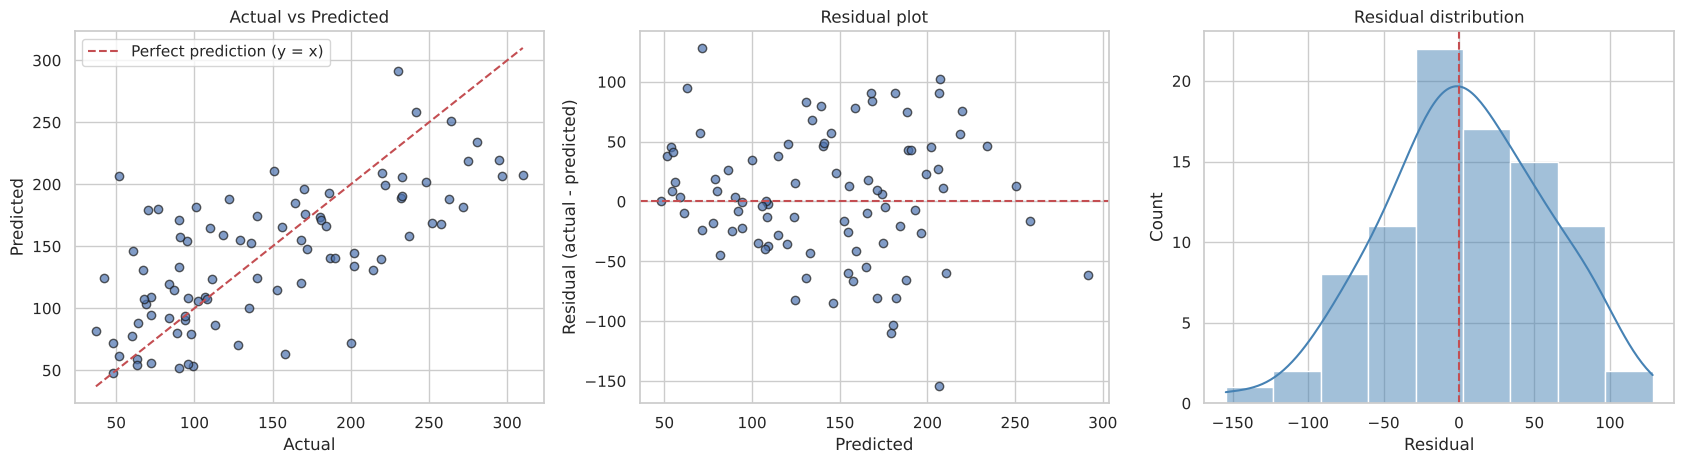

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))

# 1. Actual vs predicted
ax[0].scatter(y_test, y_pred, alpha=0.7, edgecolor="k")
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
ax[0].plot(lims, lims, "r--", label="Perfect prediction (y = x)")
ax[0].set_xlabel("Actual"); ax[0].set_ylabel("Predicted"); ax[0].set_title("Actual vs Predicted"); ax[0].legend()

# 2. Residuals vs predicted
resid = y_test - y_pred
ax[1].scatter(y_pred, resid, alpha=0.7, edgecolor="k")
ax[1].axhline(0, color="r", ls="--")
ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Residual (actual - predicted)"); ax[1].set_title("Residual plot")

# 3. Residual histogram
sns.histplot(resid, kde=True, ax=ax[2], color="steelblue")
ax[2].axvline(0, color="r", ls="--"); ax[2].set_xlabel("Residual"); ax[2].set_title("Residual distribution")
plt.tight_layout(); plt.show()

**How to read each graph**
1. **Actual vs Predicted:** each dot is one test patient. The red dashed line is perfect prediction. Dots close to the line are accurate. Here the cloud is wide around the line, matching the moderate R². The model tends to over-predict low values and under-predict high ones (the cloud is flatter than the line).
2. **Residual plot:** residual = actual minus predicted. A good model shows a random cloud centred on zero with constant spread and no pattern. A curve would mean non-linearity; a funnel shape would mean non-constant variance (heteroscedasticity).
3. **Residual histogram:** should look like a bell curve centred at zero, which supports the normality-of-errors assumption.

### Q-Q plot (normality of residuals)

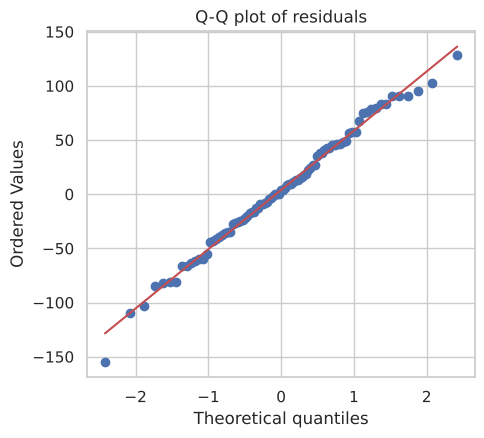

In [10]:
from scipy import stats
fig = plt.figure(figsize=(5, 4.5))
stats.probplot(resid, dist="norm", plot=plt.gca())
plt.title("Q-Q plot of residuals"); plt.show()

**How to read it:** if the residuals are normal, the dots lie on the straight red line. Deviation at the ends means heavier tails (a few large errors).

## Step 6: Multicollinearity (VIF) and cross-validation

**VIF** (Variance Inflation Factor) for feature j = $\frac{1}{1 - R_j^2}$, where $R_j^2$ is the R² from regressing feature j on the other features. VIF above 5 to 10 signals a problem.

s1     55.25
s2     35.76
s3     14.29
s5     10.07
s4      9.33
bmi     1.57
s6      1.50
bp      1.42
sex     1.27
age     1.22
Name: VIF, dtype: float64


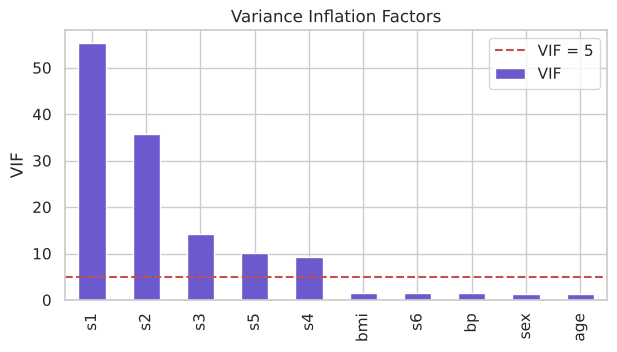

In [11]:
# VIF = diagonal of the inverse correlation matrix
corr = X_train.corr().values
vif = pd.Series(np.diag(np.linalg.inv(corr)), index=X.columns, name="VIF").sort_values(ascending=False)
print(vif.round(2))

plt.figure(figsize=(7, 3.5))
vif.plot(kind="bar", color="slateblue"); plt.axhline(5, color="r", ls="--", label="VIF = 5")
plt.ylabel("VIF"); plt.title("Variance Inflation Factors"); plt.legend(); plt.show()

**Interpretation:** `s1`, `s2` (and to a lesser extent `s3`, `s4`, `s5`) have high VIF, so these blood-serum features are strongly related to each other. This makes their individual coefficients unstable. Remedies: drop one of the correlated features, use PCA, or use Ridge/Lasso (Practical 5).

In [12]:
cv_r2 = cross_val_score(LinearRegression(), X, y, cv=5, scoring="r2")
cv_rmse = np.sqrt(-cross_val_score(LinearRegression(), X, y, cv=5, scoring="neg_mean_squared_error"))
print("5-fold R2  :", cv_r2.round(3), "| mean = %.3f" % cv_r2.mean())
print("5-fold RMSE:", cv_rmse.round(2), "| mean = %.2f" % cv_rmse.mean())

5-fold R2  : [0.43  0.523 0.483 0.426 0.55 ] | mean = 0.482
5-fold RMSE: [52.72 55.03 56.9  54.85 53.95] | mean = 54.69


Cross-validation averages over 5 different train/test splits, giving a more reliable estimate than a single split.

## Step 7: Verify with the Normal Equation (by hand)

OLS has the closed-form solution $\beta = (X^TX)^{-1}X^Ty$, where $X$ includes a column of ones for the intercept.

In [13]:
Xb = np.c_[np.ones(len(X_train)), X_train.values]
beta = np.linalg.inv(Xb.T @ Xb) @ Xb.T @ y_train.values
print("Normal-equation intercept:", round(beta[0], 3), "| sklearn:", round(model.intercept_, 3))
print("Coefficients match sklearn:", np.allclose(beta[1:], model.coef_))

Normal-equation intercept: 151.346 | sklearn: 151.346
Coefficients match sklearn: True


### Predict for one new patient

In [14]:
new_patient = X_test.iloc[[0]]
print(new_patient.round(3).to_string())
print("Predicted progression: %.1f | Actual: %.1f" % (model.predict(new_patient)[0], y_test.iloc[0]))

       age    sex    bmi     bp     s1     s2     s3     s4     s5     s6
287  0.045 -0.045 -0.006 -0.016  0.125  0.125  0.019  0.034  0.032 -0.005
Predicted progression: 139.5 | Actual: 219.0


## Result / Conclusion
- A multiple linear regression model was trained on 10 clinical features.
- Test R² is about 0.45 to 0.5 and RMSE is about 53 to 55, so the model explains about half of the variation: a moderate predictive capability.
- Train and test metrics are similar, so there is no overfitting; improvement would need more informative features, non-linear models, or regularisation.
- VIF showed multicollinearity among the serum features (`s1` to `s5`).

---
# Viva Questions and Answers

## A. Concept questions

**Q1. What is linear regression?**
A supervised algorithm that models a continuous target as a linear combination of the input features by fitting a straight line (or hyperplane).

**Q2. What is multiple linear regression? Write the equation.**
Regression with two or more features: $y = b_0 + b_1x_1 + b_2x_2 + \dots + b_nx_n + \varepsilon$, where $b_0$ is the intercept and $b_1 \dots b_n$ are coefficients.

**Q3. Difference between simple and multiple linear regression?**
Simple has one input feature; multiple has two or more.

**Q4. How are the coefficients found?**
By Ordinary Least Squares, which minimises the sum of squared residuals. Closed form: $\beta = (X^TX)^{-1}X^Ty$. Gradient descent can also be used.

**Q5. What does a coefficient mean?**
The expected change in the target for a one-unit increase in that feature, with all other features held constant.

**Q6. What is the intercept?**
The predicted value when all features are zero (here, since the features are centred, it is the average target).

**Q7. Explain MSE, RMSE and MAE.**
MSE is the average of squared errors (penalises big errors, units squared). RMSE is its square root (same units as target, easy to interpret). MAE is the average absolute error (less sensitive to outliers).

**Q8. Explain R².**
The proportion of variance in the target explained by the model. 1 is perfect, 0 means no better than predicting the mean, and it can be negative for a very bad model.

**Q9. What is adjusted R² and why use it?**
R² never decreases when you add features, even useless ones. Adjusted R² penalises extra features, so it increases only if a new feature really helps.

**Q10. What are the assumptions of linear regression?**
Linearity, independence of errors, homoscedasticity (constant error variance), normally distributed errors, and no multicollinearity. Memory aid: **LINE** (Linearity, Independence, Normality, Equal variance).

**Q11. What is multicollinearity and how do you detect it?**
When features are highly correlated with each other, making coefficients unstable. Detect with the correlation matrix or VIF (above 5 or 10 is a concern). Fix by dropping features, PCA, or Ridge regression.

**Q12. What is the difference between RMSE and R²?**
RMSE is an absolute error in the target's units (lower is better). R² is a relative, unitless measure of fit (higher is better).

**Q13. Why do we use squared error and not absolute error?**
Squared error is smooth and differentiable, gives a unique closed-form solution, and penalises large errors more.

**Q14. Is linear regression sensitive to outliers?**
Yes, because squared errors give outliers a large pull on the line.

**Q15. Is scaling needed for linear regression?**
Not for the OLS solution itself, but it helps for gradient descent, regularised models and for comparing coefficient sizes.

**Q16. How do you improve a weak R²?**
Add or engineer features, handle outliers, use polynomial features, use regularisation, or try non-linear models such as Random Forest.

**Q17. What is heteroscedasticity?**
When the variance of the errors changes across the predicted values (funnel shape in the residual plot). It violates the equal-variance assumption.

**Q18. What is the difference between regression and classification?**
Regression predicts a continuous number; classification predicts a category.

**Q19. What are the problems if train R² is high but test R² is low?**
Overfitting: the model memorised the training data. Remedies: regularisation, fewer features, more data, cross-validation.

**Q20. What is the "best fit line"?**
The line that minimises the sum of squared vertical distances between the points and the line.

**Q21. Can R² be negative?**
Yes, on test data, if the model predicts worse than simply using the mean of the target.

**Q22. What is the normal equation and when is it a bad idea?**
$\beta = (X^TX)^{-1}X^Ty$. It is slow for a very large number of features (matrix inversion is $O(p^3)$) and fails if $X^TX$ is singular (perfect multicollinearity).

## B. Questions about the graphs

**G1. What does the Actual vs Predicted plot show?**
Each dot is one test sample. The red dashed line is perfect prediction (y = x). Points near it are accurate; wide scatter means large errors.

**G2. Why is the cloud flatter than the red line?**
The model shrinks predictions toward the mean: it over-predicts low values and under-predicts high values. This is common when R² is moderate.

**G3. What does the residual plot show and what should a good one look like?**
Residual = actual minus predicted. A good plot is a random cloud around zero with constant spread and no pattern. A curve means non-linearity; a funnel shape means heteroscedasticity. Either means the linear model is not ideal.

**G4. What does the residual histogram and Q-Q plot tell you?**
Whether residuals are approximately normal. A bell shape centred at zero and dots on the Q-Q line support the normality assumption; heavy tails show a few large errors.

**G5. What does the correlation heatmap tell you?**
The pairwise correlation between variables (-1 to +1). A strong correlation between a feature and the target means a good predictor. A strong correlation between two features signals multicollinearity.

**G6. What does the single-feature regression plot show?**
A scatter of one feature versus the target with the best-fit line. The slope indicates the direction and strength of the relationship.

**G7. What does the coefficient bar chart show?**
The size and sign of each coefficient: red bars increase the target, blue bars decrease it. Because features are on the same scale here, bar length compares importance (but unstable if features are collinear).

**G8. What does the VIF bar chart show?**
How inflated each coefficient's variance is because of collinearity. Bars above the red line (5) indicate problematic features.

## C. Code questions

**C1. What do `fit()` and `predict()` do?**
`fit` learns the coefficients from training data; `predict` computes $\hat{y}$ for new data using them.

**C2. Why do we evaluate on the test set and not the training set?**
Training error is optimistic; the test set shows performance on unseen data.

**C3. What does `random_state=42` do?**
Makes the random split reproducible.

**C4. What does `model.coef_` and `model.intercept_` return?**
Coefficients (one per feature) and the intercept $b_0$.

**C5. Why `np.sqrt(mse)` for RMSE?**
RMSE is defined as the square root of MSE, which returns the error to the target's units.

**C6. What does `cross_val_score(..., cv=5)` do?**
It splits the data into 5 folds, trains on 4 and tests on 1, repeats 5 times, and returns the 5 scores.